# CA3 Capstone Project - Predicting Food Waste with Machine Learning
Dataset: Food Waste Recycling Impact - Town of Cary
https://data.townofcary.org/explore/dataset/food-waste-pilot/

In [1]:
# I used this code to import the libraries I need for data analysis and charts
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

In [2]:
# I used this code to load the dataset and see the first 5 rows
df = pd.read_csv('food-waste-pilot.csv')
df.head()

,Stop Name,Collection Date,Food Waste Collected,Estimated Earned Compost Created
0,Citizen's Convenience Center,2026-04-29,515.8,52.0
1,Mills Park,2026-04-29,537.0,54.0
2,Mills Park,2026-04-27,561.0,56.0
3,Citizen's Convenience Center,2026-04-27,1093.0,109.0
4,Citizen's Convenience Center,2026-04-24,641.6,64.0


In [3]:
# I used this code to check the size of the dataset (rows, columns)
df.shape

(1006, 4)

i saw, the dataset has 1006 rows and 4 columns.

In [4]:
# I used this code to check the data type of each column and see if there are empty values
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1006 entries, 0 to 1005
Data columns (total 4 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   Stop Name                         1006 non-null   str    
 1   Collection Date                   1006 non-null   str    
 2   Food Waste Collected              1006 non-null   float64
 3   Estimated Earned Compost Created  1006 non-null   float64
dtypes: float64(2), str(2)
memory usage: 62.7 KB


In [5]:
# I used this code to see the main statistics of the numeric columns
df.describe()

,Food Waste Collected,Estimated Earned Compost Created
count,1006.000000,1006.000000
mean,644.130219,64.382704
std,307.244105,30.726067
min,0.000000,0.000000
25%,452.900000,45.000000
50%,598.400000,60.000000
75%,762.975000,76.000000
max,2057.000000,206.000000


i can see, the average food waste per collection is about 644 lbs. The minimum is 0 lbs, which may mean the site was closed that day, and the maximum is about 2,057 lbs, which may be an outlier.

In [6]:
# I used this code to see how many collections each drop-off site has
df['Stop Name'].value_counts()

Stop Name
Citizen's Convenience Center    656
Mills Park                      350
Name: count, dtype: int64

As we can see, there are 2 sites: Citizen's Convenience Center (656 collections) and Mills Park (350 collections). Our target is Food Waste Collected.

In [7]:
# I used this code to check if there are missing values in each column
df.isnull().sum()

Stop Name                           0
Collection Date                     0
Food Waste Collected                0
Estimated Earned Compost Created    0
dtype: int64

So, there are no missing values in the dataset.

In [8]:
# I used this code to convert the Collection Date from text to a real date,
# so I can sort the data by time and create date features later
df['Collection Date'] = pd.to_datetime(df['Collection Date'])
df['Collection Date'].min(), df['Collection Date'].max()

(Timestamp('2022-02-02 00:00:00'), Timestamp('2026-04-29 00:00:00'))

i saw, the data covers more than 4 years, from February 2022 to April 2026.

In [9]:
# I used this code to find duplicated collections
df[df.duplicated(['Stop Name', 'Collection Date'], keep=False)]

,Stop Name,Collection Date,Food Waste Collected,Estimated Earned Compost Created
463,Citizen's Convenience Center,2024-11-01,867.0,87.0
464,Citizen's Convenience Center,2024-11-01,481.8,48.0


In [10]:
# I used this code to add the two pickups together, so each site has only one row per day
df = df.groupby(['Stop Name', 'Collection Date'], as_index=False)[['Food Waste Collected', 'Estimated Earned Compost Created']].sum()
df.shape

(1005, 4)

i see, the dataset now has 1005 rows.

In [11]:
# I used this code to find the collections with 0 lbs of food waste
df[df['Food Waste Collected'] == 0]

,Stop Name,Collection Date,Food Waste Collected,Estimated Earned Compost Created
0,Citizen's Convenience Center,2022-02-02,0.0,0.0
90,Citizen's Convenience Center,2022-09-05,0.0,0.0
119,Citizen's Convenience Center,2022-11-11,0.0,0.0
147,Citizen's Convenience Center,2023-01-16,0.0,0.0
209,Citizen's Convenience Center,2023-06-19,0.0,0.0
298,Citizen's Convenience Center,2024-01-15,0.0,0.0
364,Citizen's Convenience Center,2024-06-19,0.0,0.0
456,Citizen's Convenience Center,2025-01-20,0.0,0.0
457,Citizen's Convenience Center,2025-01-22,0.0,0.0
493,Citizen's Convenience Center,2025-04-17,0.0,0.0


from this table i see, there are 15 collections with 0 lbs. These dates are public holidays In the USA (for example Labor Day and Juneteenth), so the site was closed. A 0 here does not mean "no food waste", so I will remove these rows.

In [12]:
# I used this code to remove the days when the site was closed
df = df[df['Food Waste Collected'] > 0]
df.shape

(990, 4)

In [13]:
# I used this code to check the first collections at Mills Park
df[df['Stop Name'] == 'Mills Park'].sort_values('Collection Date').head()

,Stop Name,Collection Date,Food Waste Collected,Estimated Earned Compost Created
655,Mills Park,2022-08-25,664.8,66.0
657,Mills Park,2024-02-02,66.4,7.0
658,Mills Park,2024-02-05,171.8,17.0
659,Mills Park,2024-02-07,207.0,21.0
660,Mills Park,2024-02-09,181.4,18.0


i saw there is one Mills Park collection in August 2022, and then nothing Until January 2024. Mills Park opened in 2024, so this row is probably a data entry error.

In [14]:
# I used this code to remove the wrong Mills Park row from 2022
df = df[~((df['Stop Name'] == 'Mills Park') & (df['Collection Date'] < '2024-01-01'))]
df.shape

(989, 4)

In [15]:
# I used this code to check the correlation between the food waste and the compost created
df[['Food Waste Collected', 'Estimated Earned Compost Created']].corr()

,Food Waste Collected,Estimated Earned Compost Created
Food Waste Collected,1.000000,0.999952
Estimated Earned Compost Created,0.999952,1.000000


In [16]:
# I used this code to remove the compost column to avoid data leakage
df = df.drop('Estimated Earned Compost Created', axis=1)
df.head()

,Stop Name,Collection Date,Food Waste Collected
1,Citizen's Convenience Center,2022-02-09,59.0
2,Citizen's Convenience Center,2022-02-11,197.0
3,Citizen's Convenience Center,2022-02-14,329.4
4,Citizen's Convenience Center,2022-02-16,102.8
5,Citizen's Convenience Center,2022-02-18,202.8


i see, the dataset now has only 3 columns: Stop Name, Collection Date and Food Waste Collected.

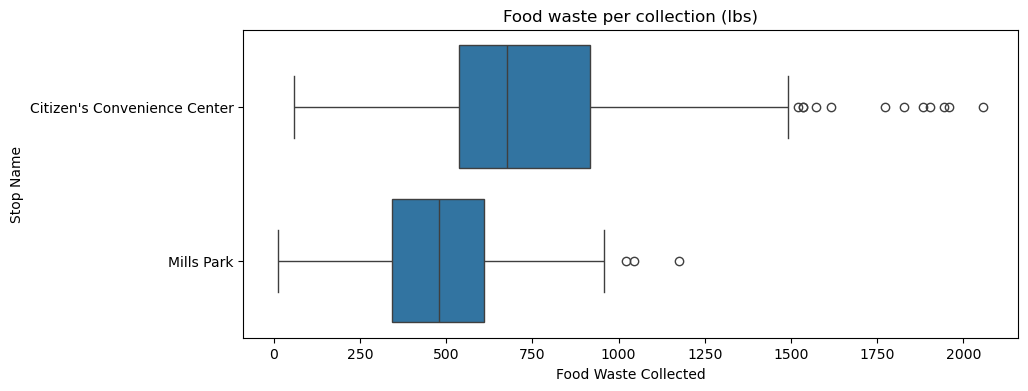

In [17]:
# I used this code to look for outliers in the food waste for each site
plt.figure(figsize=(10, 4))
sns.boxplot(x='Food Waste Collected', y='Stop Name', data=df)
plt.title('Food waste per collection (lbs)')
plt.show()

In [18]:
# I used this code to count the outliers with the IQR method and see on which days they happen
Q1 = df['Food Waste Collected'].quantile(0.25)
Q3 = df['Food Waste Collected'].quantile(0.75)
IQR = Q3 - Q1
outliers = df[df['Food Waste Collected'] > Q3 + 1.5 * IQR]
print('Number of outliers:', len(outliers))
outliers['Collection Date'].dt.day_name().value_counts()

Number of outliers: 55


Collection Date
Monday       44
Wednesday     5
Tuesday       3
Friday        3
Name: count, dtype: int64

i can see, there are 55 outliers and 44 of them are on Mondays. On Monday, the site collects the food waste of the whole weekend, so the amount is bigger. These values are real, no errors, so I will keep them.

#### Exploratory Data Analysis (EDA)

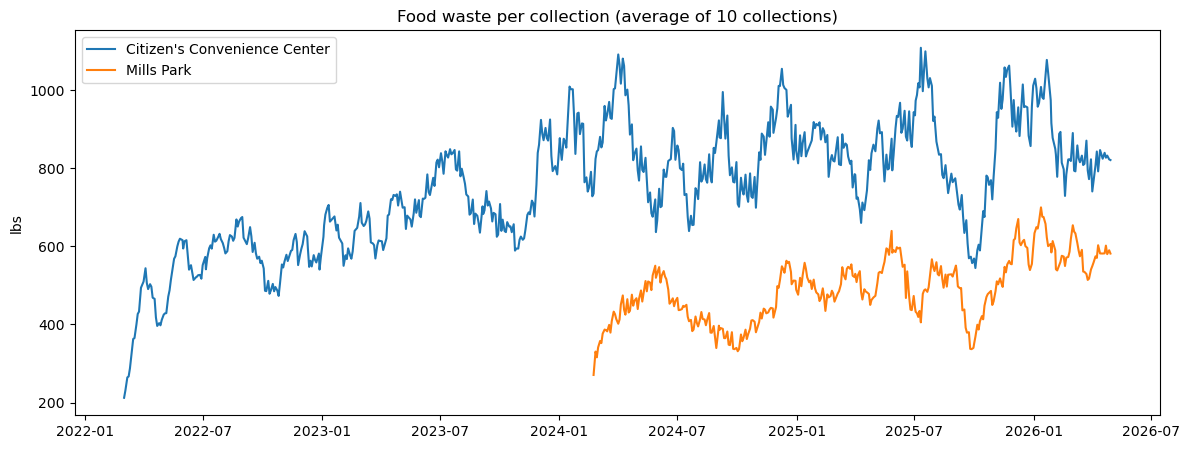

In [19]:
# I used this code to see how the food waste changes over time at each site.
# I used a rolling average of 10 collections to make the trend easier to see.
plt.figure(figsize=(14, 5))
for site in df['Stop Name'].unique():
    s = df[df['Stop Name'] == site].set_index('Collection Date')['Food Waste Collected']
    plt.plot(s.rolling(10).mean(), label=site)
plt.title('Food waste per collection (average of 10 collections)')
plt.ylabel('lbs')
plt.legend()
plt.show()

i saw, Citizen's Convenience Center has been collecting food waste since 2022, and Mills Park only since 2024. The amount per collection goes up and down, but there is a general increase over time.

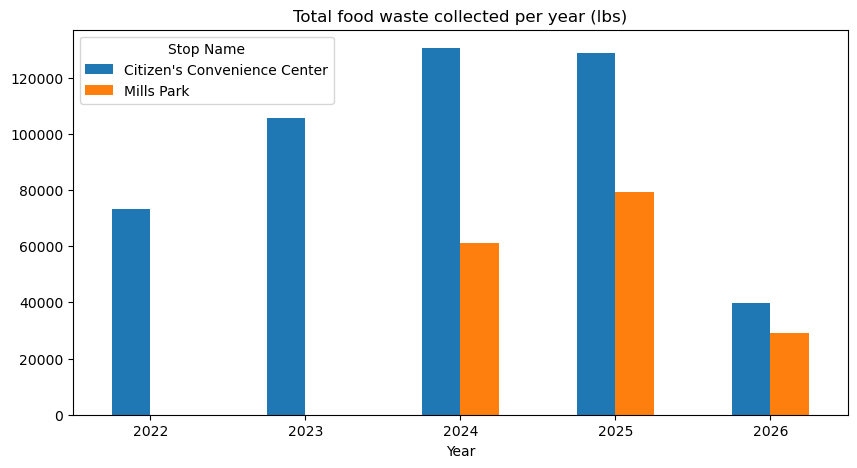

In [20]:
# I used this code to compare the total food waste collected each year at each site
df.groupby([df['Collection Date'].dt.year, 'Stop Name'])['Food Waste Collected'].sum().unstack().plot.bar(figsize=(10, 5))
plt.title('Total food waste collected per year (lbs)')
plt.xlabel('Year')
plt.xticks(rotation=0)
plt.show()

from this chart i see, the food waste collected at Citizen's Convenience Center increased from about 73,000 lbs in 2022 to about 130,000 lbs in 2024. Mills Park also increased, From about 61,000 lbs in 2024 to about 79,000 lbs in 2025. This shows that more and more residents use the service. 2026 is lower because the data stops in April.

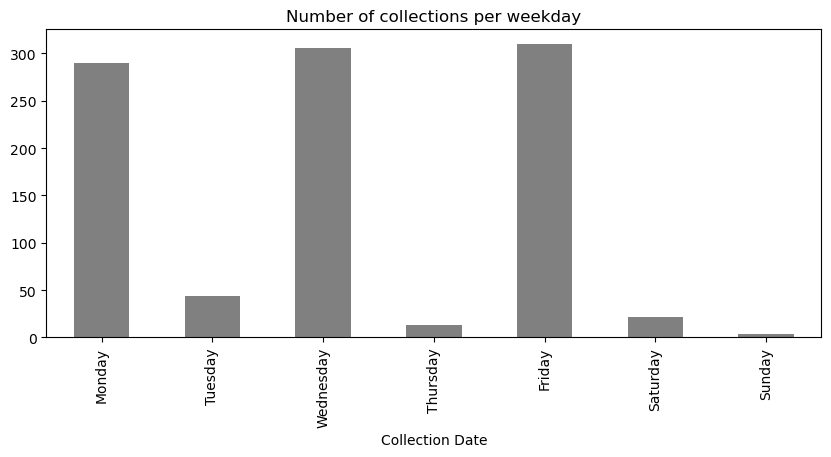

In [21]:
# I used this code to see on which days of the week the collections happen
order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
df['Collection Date'].dt.day_name().value_counts().reindex(order).plot.bar(figsize=(10, 4), color='grey')
plt.title('Number of collections per weekday')
plt.show()

most collections happen on Monday, Wednesday and Friday (about 300 each). The other days are rare.

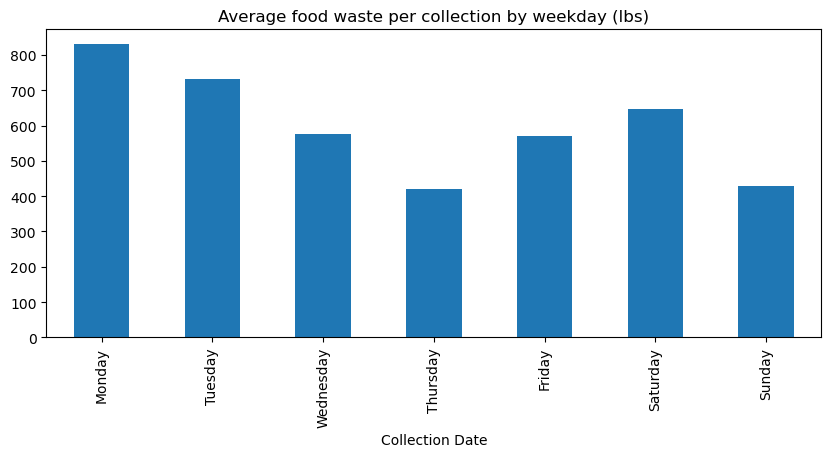

In [22]:
# I used this code to compare the average food waste for each day of the week
df.groupby(df['Collection Date'].dt.day_name())['Food Waste Collected'].mean().reindex(order).plot.bar(figsize=(10, 4))
plt.title('Average food waste per collection by weekday (lbs)')
plt.show()

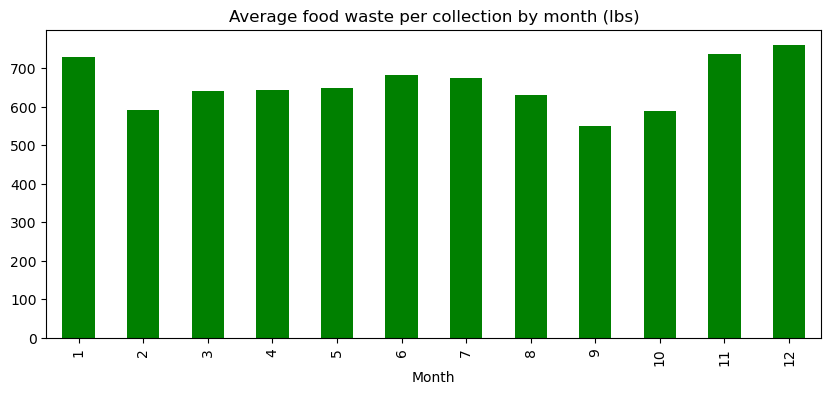

In [23]:
# I used this code to see if the food waste changes with the month of the year (seasonality)
df.groupby(df['Collection Date'].dt.month)['Food Waste Collected'].mean().plot.bar(figsize=(10, 4), color='green')
plt.title('Average food waste per collection by month (lbs)')
plt.xlabel('Month')
plt.show()

i see, November, December and January have the highest food waste (about 730-760 lbs per collection), probably because of the holidays (Thanksgiving, Christmas). September and October are the lowest.

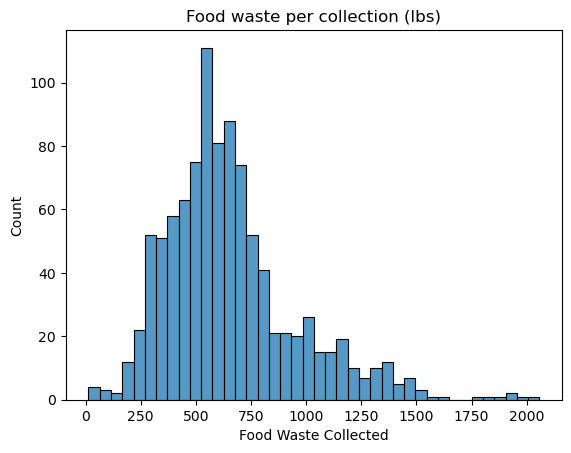

In [24]:
# I used this code to see the distribution of the target (Food Waste Collected)
sns.histplot(df['Food Waste Collected'], bins=40)
plt.title('Food waste per collection (lbs)')
plt.show()

i can see, most collections are between about 460 and 770 lbs. The distribution is right-skewed: a few collections are much bigger (up to about 2,057 lbs), mostly on Mondays.

#### Feature Engineering

In [25]:
# I used this code to sort the data by site and by date,
# because the lag features need the collections in the right time order
df = df.sort_values(['Stop Name', 'Collection Date']).reset_index(drop=True)
g = df.groupby('Stop Name')

In [26]:
# I used this code to create calendar features from the date,
# because the EDA showed that the weekday and the month change the food waste
df['day_of_week'] = df['Collection Date'].dt.dayofweek   # 0 = Monday
df['month'] = df['Collection Date'].dt.month
df['year'] = df['Collection Date'].dt.year
df['is_monday'] = np.where(df['day_of_week'] == 0, 1, 0)
df.head()

,Stop Name,Collection Date,Food Waste Collected,day_of_week,month,year,is_monday
0,Citizen's Convenience Center,2022-02-09,59.0,2,2,2022,0
1,Citizen's Convenience Center,2022-02-11,197.0,4,2,2022,0
2,Citizen's Convenience Center,2022-02-14,329.4,0,2,2022,1
3,Citizen's Convenience Center,2022-02-16,102.8,2,2,2022,0
4,Citizen's Convenience Center,2022-02-18,202.8,4,2,2022,0


In [27]:
# I used this code to calculate the number of days since the previous collection at the same site,
# because more days (weekend, holidays) means more food waste.
# I also calculated how long the site has been open, because the service grows over time.
df['days_since_last'] = g['Collection Date'].diff().dt.days
df['site_age_days'] = (df['Collection Date'] - g['Collection Date'].transform('min')).dt.days
df.head()

,Stop Name,Collection Date,Food Waste Collected,day_of_week,month,year,is_monday,days_since_last,site_age_days
0,Citizen's Convenience Center,2022-02-09,59.0,2,2,2022,0,NaN,0
1,Citizen's Convenience Center,2022-02-11,197.0,4,2,2022,0,2.0,2
2,Citizen's Convenience Center,2022-02-14,329.4,0,2,2022,1,3.0,5
3,Citizen's Convenience Center,2022-02-16,102.8,2,2,2022,0,2.0,7
4,Citizen's Convenience Center,2022-02-18,202.8,4,2,2022,0,2.0,9


In [28]:
# I used this code to create lag features: the food waste of the previous collections.
# shift() only takes values from the past, so there is no data leakage.
df['lag_1'] = g['Food Waste Collected'].shift(1)   # previous collection
df['lag_2'] = g['Food Waste Collected'].shift(2)   # 2 collections before
df['lag_3'] = g['Food Waste Collected'].shift(3)   # about the same weekday last week
df.head()

,Stop Name,Collection Date,Food Waste Collected,day_of_week,month,year,is_monday,days_since_last,site_age_days,lag_1,lag_2,lag_3
0,Citizen's Convenience Center,2022-02-09,59.0,2,2,2022,0,NaN,0,NaN,NaN,NaN
1,Citizen's Convenience Center,2022-02-11,197.0,4,2,2022,0,2.0,2,59.0,NaN,NaN
2,Citizen's Convenience Center,2022-02-14,329.4,0,2,2022,1,3.0,5,197.0,59.0,NaN
3,Citizen's Convenience Center,2022-02-16,102.8,2,2,2022,0,2.0,7,329.4,197.0,59.0
4,Citizen's Convenience Center,2022-02-18,202.8,4,2,2022,0,2.0,9,102.8,329.4,197.0


In [29]:
# I used this code to calculate the average of the past collections (rolling averages),
# to give the model the recent level of food waste.
# I used shift(1) first, so the current collection is NOT included (no data leakage).
df['rolling_mean_3'] = g['Food Waste Collected'].transform(lambda s: s.shift(1).rolling(3).mean())
df['rolling_mean_6'] = g['Food Waste Collected'].transform(lambda s: s.shift(1).rolling(6).mean())
df['rolling_mean_12'] = g['Food Waste Collected'].transform(lambda s: s.shift(1).rolling(12).mean())
df.head(15)

,Stop Name,Collection Date,Food Waste Collected,day_of_week,month,year,is_monday,days_since_last,site_age_days,lag_1,lag_2,lag_3,rolling_mean_3,rolling_mean_6,rolling_mean_12
0,Citizen's Convenience Center,2022-02-09,59.0,2,2,2022,0,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN
1,Citizen's Convenience Center,2022-02-11,197.0,4,2,2022,0,2.0,2,59.0,NaN,NaN,NaN,NaN,NaN
2,Citizen's Convenience Center,2022-02-14,329.4,0,2,2022,1,3.0,5,197.0,59.0,NaN,NaN,NaN,NaN
3,Citizen's Convenience Center,2022-02-16,102.8,2,2,2022,0,2.0,7,329.4,197.0,59.0,195.133333,NaN,NaN
4,Citizen's Convenience Center,2022-02-18,202.8,4,2,2022,0,2.0,9,102.8,329.4,197.0,209.733333,NaN,NaN
5,Citizen's Convenience Center,2022-02-21,183.8,0,2,2022,1,3.0,12,202.8,102.8,329.4,211.666667,NaN,NaN
6,Citizen's Convenience Center,2022-02-23,283.0,2,2,2022,0,2.0,14,183.8,202.8,102.8,163.133333,179.133333,NaN
7,Citizen's Convenience Center,2022-02-25,250.8,4,2,2022,0,2.0,16,283.0,183.8,202.8,223.200000,216.466667,NaN
8,Citizen's Convenience Center,2022-02-28,213.8,0,2,2022,1,3.0,19,250.8,283.0,183.8,239.200000,225.433333,NaN
9,Citizen's Convenience Center,2022-03-02,298.8,2,3,2022,0,2.0,21,213.8,250.8,283.0,249.200000,206.166667,NaN


In [30]:
# I used this code to remove the first rows of each site that have no history
df = df.dropna().reset_index(drop=True)
df.shape

(965, 15)

In [31]:
# I used this code to change Stop Name (text) into a number (0 or 1),
# because machine learning models only work with numbers
site = pd.get_dummies(df['Stop Name'], drop_first=True, dtype=int)
data = pd.concat([df, site], axis=1)
data.head()

,Stop Name,Collection Date,Food Waste Collected,day_of_week,month,year,is_monday,days_since_last,site_age_days,lag_1,lag_2,lag_3,rolling_mean_3,rolling_mean_6,rolling_mean_12,Mills Park
0,Citizen's Convenience Center,2022-03-09,352.8,2,3,2022,0,2.0,28,531.2,246.8,298.8,358.933333,304.066667,241.600000,0
1,Citizen's Convenience Center,2022-03-11,309.4,4,3,2022,0,2.0,30,352.8,531.2,246.8,376.933333,315.700000,266.083333,0
2,Citizen's Convenience Center,2022-03-14,659.2,0,3,2022,1,3.0,33,309.4,352.8,531.2,397.800000,325.466667,275.450000,0
3,Citizen's Convenience Center,2022-03-16,481.8,2,3,2022,0,2.0,35,659.2,309.4,352.8,440.466667,399.700000,302.933333,0
4,Citizen's Convenience Center,2022-03-18,303.8,4,3,2022,0,2.0,37,481.8,659.2,309.4,483.466667,430.200000,334.516667,0


In [32]:
# I used this code to separate the features (X) from the target (y).
# I removed the text and date columns, and the target itself.
X = data.drop(['Stop Name', 'Collection Date', 'Food Waste Collected'], axis=1)
y = data['Food Waste Collected']
X.head()

,day_of_week,month,year,is_monday,days_since_last,site_age_days,lag_1,lag_2,lag_3,rolling_mean_3,rolling_mean_6,rolling_mean_12,Mills Park
0,2,3,2022,0,2.0,28,531.2,246.8,298.8,358.933333,304.066667,241.600000,0
1,4,3,2022,0,2.0,30,352.8,531.2,246.8,376.933333,315.700000,266.083333,0
2,0,3,2022,1,3.0,33,309.4,352.8,531.2,397.800000,325.466667,275.450000,0
3,2,3,2022,0,2.0,35,659.2,309.4,352.8,440.466667,399.700000,302.933333,0
4,4,3,2022,0,2.0,37,481.8,659.2,309.4,483.466667,430.200000,334.516667,0


In [33]:
# I used this code to split the data by time, not randomly:
# before July 2025 = train, from July 2025 = test.
# A random split would let the model learn from the future, which is not realistic.
train_idx = data['Collection Date'] < '2025-07-01'
test_idx = data['Collection Date'] >= '2025-07-01'

X_train, X_test = X[train_idx], X[test_idx]
y_train, y_test = y[train_idx], y[test_idx]
X_train.shape, X_test.shape

((710, 13), (255, 13))

i see, the train set has 710 collections and the test set has 255 collections (about 74% / 26%). The test set is the last 10 months (July 2025 - April 2026).